# 03. Volatilité conditionnelle de l'or : ARMA-GARCH, mémoire longue et covariables

**Projet :** Prévision de l'or (XAU/USD) — *Advanced Time Series* (ENSAI, 3A)

### Plan
0. Mise en place (or + covariables, découpage train / test = **3 derniers jours**)
1. Pourquoi un GARCH ? (Ljung-Box, ARCH-LM)
2. Courte ou longue mémoire ? (ACF longues, estimateur GPH de $d$)
3. Équation de moyenne : ARMA par BIC + QMLE jointe ARMA(1,1)-GARCH(1,1) codée à la main (inspirée de l'Atelier 2)
4. Équation de variance : GARCH, GJR-GARCH, EGARCH, FIGARCH × {Normale, Student-t, Skew-t}
5. Diagnostics et choix du modèle univarié
6. **Covariables** (dollar, VIX, taux 10 ans, pétrole, S&P 500) dans la moyenne et dans la variance (GARCH-X)
7. Prévision des 3 jours de test
8. Évaluation sur les 3 jours (RMSE en rendement et en prix)
9. Export des prévisions pour `06_evaluation.ipynb`

*Annexe :* simulation Monte Carlo de l'Atelier 2 (estimateur des moindres carrés d'un ARMA à erreurs ARCH).

**Modèle général :**
$$r_t = \mu_t + \varepsilon_t,\qquad \varepsilon_t = \sigma_t z_t,\qquad z_t \overset{iid}{\sim} D(0,1)$$
où $\mu_t$ suit un ARMA$(p,q)$ (éventuellement avec covariables) et $\sigma_t^2$ un modèle de la famille GARCH (éventuellement avec covariables).

## 0. Mise en place

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.signal import lfilter
from scipy.optimize import minimize
from scipy.special import xlogy

from arch import arch_model
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf

warnings.filterwarnings("ignore")  # avertissements de convergence statsmodels / arch

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["font.size"] = 11
plt.rcParams["lines.linewidth"] = 1.5

# Palette fixe (une couleur = un modèle, dans tout le notebook)
COL = {"data": "#555555", "GARCH": "#2a78d6", "GJR": "#eb6834", "EGARCH": "#1baf7a",
       "FIGARCH": "#eda100", "EWMA": "#e87ba4", "Roll20": "#8c8c8c", "Chronos": "#7b4fd6"}

DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 2026

**Données.**
- Or : log-rendements en pourcentage, $r_t = 100\,\ln(P_t/P_{t-1})$ (le facteur 100 aide la convergence numérique de `arch`). On reste sur le calendrier de cotation de l'or, **sans** réindexer en jours ouvrés avec `ffill` : cela créerait de faux rendements nuls les jours fériés.
- Covariables (`covariates_daily.csv`) : quelques jours fériés diffèrent de ceux de l'or. On prend la **dernière valeur connue** (`ffill`) à chaque date de l'or. On les transforme en séries stationnaires, en % :

| Variable | Transformation | Idée économique |
|---|---|---|
| `DXY` (dollar) | $100\,\Delta\ln$ | l'or est coté en dollars : un dollar fort pèse sur l'or |
| `dVIX` (volatilité implicite actions) | $100\,\Delta\ln$ | stress de marché → demande de valeur refuge |
| `dTNX` (taux US à 10 ans) | $100\,\Delta$ (en points de base) | taux réels plus hauts → coût d'opportunité de l'or |
| `OIL` (pétrole WTI) | $100\,\Delta\ln$ | anticipations d'inflation, matières premières |
| `SP500` | $100\,\Delta\ln$ | appétit pour le risque |

Le WTI a coté **négativement** le 20 avril 2020 : son log-rendement n'est pas défini ce jour-là et le suivant. On le remplace par 0.

**Pas de fuite d'information :** pour prévoir $r_t$, on ne connaît les covariables que jusqu'à la veille. Toutes les covariables entrent donc **décalées d'un jour** ($X_{t-1}$).

**Découpage :** *train* = tout sauf les **3 derniers jours de cotation** ; *test* = ces 3 jours. Avec seulement 3 points, les métriques de test sont très bruitées. L'intérêt des covariables est donc jugé surtout **dans l'échantillon d'apprentissage** (≈ 5 500 jours), par des tests du rapport de vraisemblance et des écarts-types robustes.

In [2]:
gold = pd.read_csv(DATA_DIR / "gold_daily.csv", parse_dates=["Date"], index_col="Date")
cov = pd.read_csv(DATA_DIR / "covariates_daily.csv", parse_dates=["Date"], index_col="Date")
cov = cov.reindex(cov.index.union(gold.index)).ffill().reindex(gold.index)   # calendrier de l'or

def log_ret(s):
    return 100 * np.log(s.where(s > 0)).diff()

feat = pd.DataFrame({
    "DXY": log_ret(cov["DXY"]),
    "dVIX": log_ret(cov["VIX"]),
    "dTNX": 100 * cov["TNX_10Y"].diff(),
    "OIL": log_ret(cov["OIL"]).fillna(0.0),   # WTI négatif en avril 2020
    "SP500": log_ret(cov["SP500"]),
})
MEAN_VARS = list(feat.columns)

# Variables de variance : grandeurs positives (pour garantir sigma^2 > 0)
var_feat = pd.DataFrame({
    "VIX2": cov["VIX"] ** 2 / 252,     # variance journalière implicite du S&P 500, en %^2
    "SP500_2": feat["SP500"] ** 2,
    "DXY_2": feat["DXY"] ** 2,
    "OIL_2": feat["OIL"] ** 2,
    "dTNX_2": feat["dTNX"] ** 2 / 100,  # (pb)^2 / 100 pour une échelle comparable
})
VAR_VARS = list(var_feat.columns)

data = pd.concat([
    (100 * np.log(gold["Close"]).diff()).rename("r"),
    feat.shift(1),                         # X_{t-1} dans l'équation de moyenne
    var_feat.shift(1).add_prefix("v_"),    # Z_{t-1} dans l'équation de variance
], axis=1).dropna()
price = gold["Close"]

N_TEST = 3
r = data["r"]
train, test = r.iloc[:-N_TEST], r.iloc[-N_TEST:]
T0 = len(train)

print(f"Observations : {len(r)}  ({r.index[0].date()} -> {r.index[-1].date()})")
print(f"Train : {len(train)}  ({train.index[0].date()} -> {train.index[-1].date()})")
print(f"Test  : {len(test)}  -> {[d.date().isoformat() for d in test.index]}")
print(f"Rendements exactement nuls (jours sans cotation) : {(r == 0).sum()}")
data.describe().T[["mean", "std", "min", "max"]].round(3)

Observations : 5503  (2005-01-05 -> 2026-11-24)
Train : 5500  (2005-01-05 -> 2026-11-19)
Test  : 3  -> ['2026-11-20', '2026-11-23', '2026-11-24']
Rendements exactement nuls (jours sans cotation) : 29


,mean,std,min,max
r,0.039,1.169,-11.406,8.643
DXY,0.005,0.472,-2.717,2.524
dVIX,0.012,7.625,-44.245,76.825
dTNX,0.013,5.614,-47.000,33.200
OIL,0.023,2.657,-28.221,31.963
SP500,0.033,1.200,-12.765,10.957
v_VIX2,1.738,2.137,0.332,27.133
v_SP500_2,1.441,5.594,0.000,162.951
v_DXY_2,0.222,0.450,0.000,7.382
v_OIL_2,7.058,30.709,0.000,1021.657


## 1. Pourquoi un GARCH ?

- **Ljung-Box** sur $r_t$ : y a-t-il de l'autocorrélation linéaire (donc un ARMA à modéliser) ?
- **Ljung-Box** sur $r_t^2$ et **test ARCH-LM d'Engle** ($H_0$ : pas d'effet ARCH) : la variance dépend-elle du passé ?

In [3]:
def lb_table(x, lags=(5, 10, 20)):
    t = acorr_ljungbox(x, lags=list(lags))
    return t["lb_pvalue"]

tests = pd.DataFrame({
    "LB p-value r_t": lb_table(train),
    "LB p-value r_t^2": lb_table(train**2),
})
tests.index.name = "retard"
print(tests.map(lambda v: f"{v:.2e}"))

for L in (5, 10):
    lm, lm_p, _, _ = het_arch(train - train.mean(), nlags=L)
    print(f"ARCH-LM ({L} retards) : stat = {lm:.1f}, p-value = {lm_p:.2e}")

       LB p-value r_t LB p-value r_t^2
retard                                
5            2.74e-01         2.49e-73
10           8.49e-03        3.14e-111
20           1.79e-02        9.28e-162
ARCH-LM (5 retards) : stat = 243.2, p-value = 1.57e-50
ARCH-LM (10 retards) : stat = 298.2, p-value = 3.79e-58


**Commentaire.**
- Sur $r_t$, le Ljung-Box semble détecter une faible autocorrélation à 10 et 20 retards (p = 0,008 et 0,018), mais pas à 5 (p = 0,27). **Ce test suppose des observations iid sous $H_0$.** Avec un effet ARCH, la variance des autocorrélations empiriques est sous-estimée et le test rejette trop souvent. C'est le message de l'Atelier 2 (et de l'annexe). On refera donc le test sur les résidus standardisés en section 5.
- Sur $r_t^2$, les p-values sont inférieures à $10^{-70}$ et l'ARCH-LM rejette massivement (p < $10^{-49}$) : **forte hétéroscédasticité conditionnelle**. Un modèle de type GARCH est nécessaire.

## 2. Courte ou longue mémoire ?

Pour un processus à **mémoire longue**, l'ACF décroît hyperboliquement ($\rho(h) \sim c\,h^{2d-1}$) au lieu d'exponentiellement. On regarde l'ACF jusqu'à 200 retards pour $r_t$, $|r_t|$ et $r_t^2$.

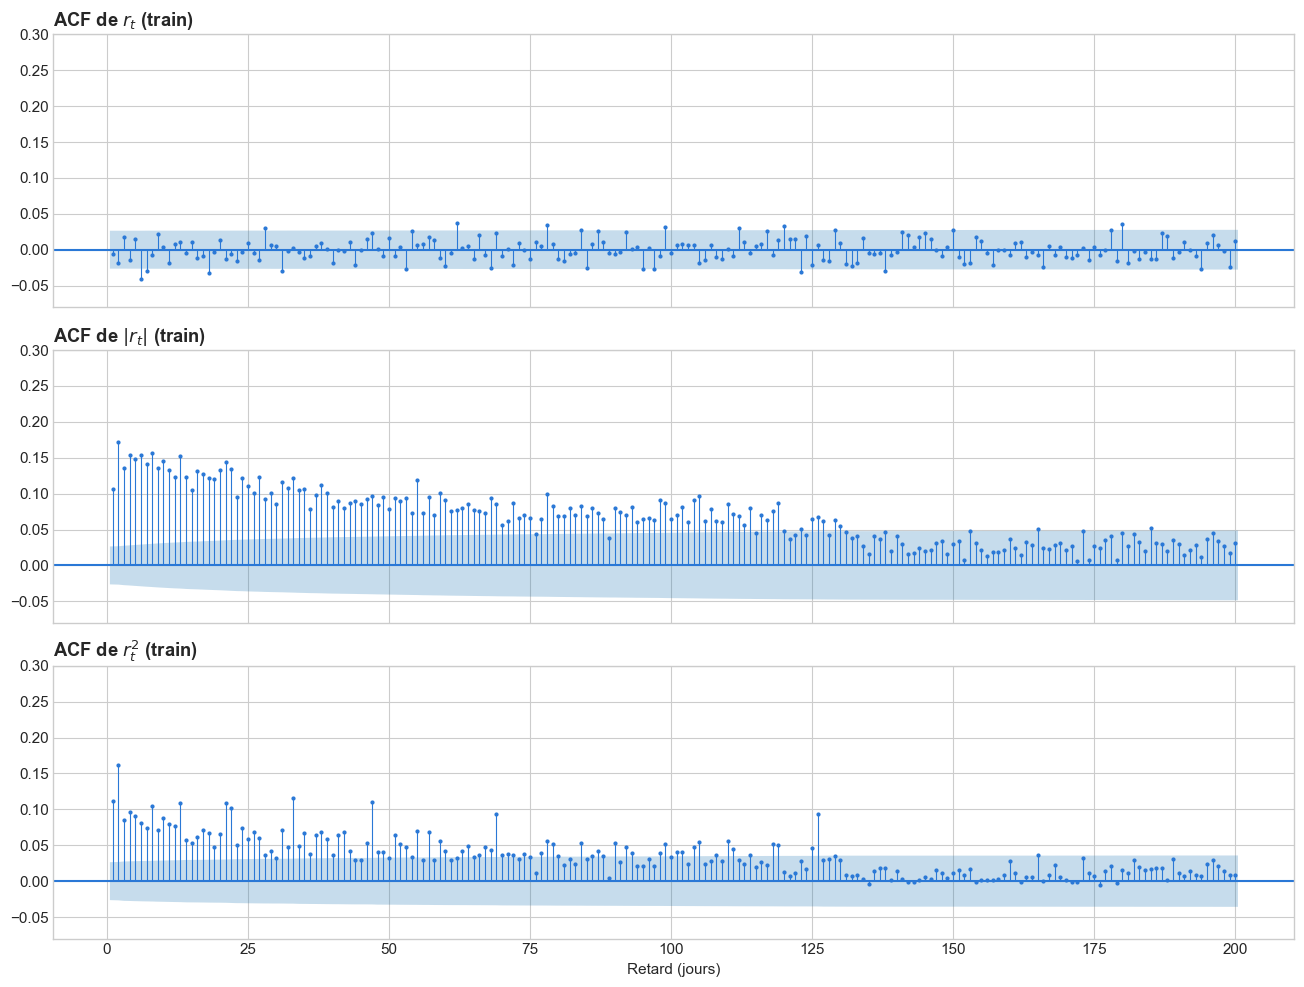

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, (x, name) in zip(axes, [(train, "r_t"), (train.abs(), "|r_t|"), (train**2, "r_t^2")]):
    plot_acf(x, lags=200, zero=False, ax=ax, markersize=2, color=COL["GARCH"],
             vlines_kwargs={"colors": COL["GARCH"], "linewidth": 0.8})
    ax.set_title("")  # retire le titre centré "Autocorrelation" de statsmodels
    ax.set_title(f"ACF de ${name}$ (train)", fontweight="bold", loc="left")
    ax.set_ylim(-0.08, 0.3)
axes[-1].set_xlabel("Retard (jours)")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_acf_long_memory.png", dpi=200)
plt.show()

**Estimation de $d$ : estimateur GPH (Geweke & Porter-Hudak, 1983).**
Au voisinage de la fréquence nulle, la densité spectrale d'un processus $I(d)$ vérifie $f(\lambda) \sim c\,\lambda^{-2d}$. On régresse le log-périodogramme sur les $m$ premières fréquences de Fourier :
$$\ln I(\lambda_j) = c - d\,\ln\!\big(4\sin^2(\lambda_j/2)\big) + u_j,\qquad j=1,\dots,m,$$
avec $m = n^{0.5}$ ou $n^{0.6}$. L'écart-type asymptotique vaut $\pi/\sqrt{6\sum_j (x_j-\bar x)^2}$.
- $d = 0$ : mémoire courte ; $0 < d < 0.5$ : mémoire longue stationnaire.

In [5]:
def gph(x, power=0.5):
    """Estimateur GPH de d (log-périodogramme). Renvoie (d, écart-type, m)."""
    x = np.asarray(x, dtype=float) - np.mean(x)
    n = len(x)
    m = int(n**power)
    I = np.abs(np.fft.fft(x)) ** 2 / (2 * np.pi * n)
    lam = 2 * np.pi * np.arange(1, m + 1) / n
    reg = -np.log(4 * np.sin(lam / 2) ** 2)
    X = np.column_stack([np.ones(m), reg])
    beta = np.linalg.lstsq(X, np.log(I[1 : m + 1]), rcond=None)[0]
    se = np.pi / np.sqrt(6 * np.sum((reg - reg.mean()) ** 2))
    return beta[1], se, m

rows = []
for x, name in [(train, "r_t"), (train.abs(), "|r_t|"), (train**2, "r_t^2")]:
    for p in (0.5, 0.6):
        d, se, m = gph(x, p)
        rows.append({"série": name, "m": f"n^{p} = {m}", "d estimé": d, "e.-t.": se,
                     "p-value (H0 : d=0)": 2 * (1 - stats.norm.cdf(abs(d / se)))})
gph_table = pd.DataFrame(rows).set_index(["série", "m"])
print(gph_table.round(3))

                   d estimé  e.-t.  p-value (H0 : d=0)
série m                                               
r_t   n^0.5 = 74      0.064  0.082               0.437
      n^0.6 = 175     0.024  0.051               0.636
|r_t| n^0.5 = 74      0.457  0.082               0.000
      n^0.6 = 175     0.421  0.051               0.000
r_t^2 n^0.5 = 74      0.353  0.082               0.000
      n^0.6 = 175     0.251  0.051               0.000


**Commentaire.**
- L'ACF de $r_t$ ne montre aucune structure. Quelques pics isolés (au plus ±0,04) dépassent les bandes : 21 retards sur 200 avec la bande iid ±1,96/√n, un peu plus que les 5 % attendus. Ils n'ont aucun motif régulier, et ces bandes supposent des données iid, ce que l'effet ARCH invalide (même argument que pour le Ljung-Box). Pas de mémoire exploitable dans les rendements.
- Les ACF de $|r_t|$ et $r_t^2$ sont positives et significatives sur plus d'une centaine de retards, avec une décroissance **lente (hyperbolique)** plutôt qu'exponentielle. C'est la signature d'une mémoire longue de la volatilité. L'effet est plus net sur $|r_t|$, moins sensible aux valeurs extrêmes (« effet Taylor »).
- **GPH :** pour $r_t$, $\hat d$ vaut 0,06 et 0,02, non significatif (p = 0,44 et 0,64), donc **un ARFIMA n'est pas justifié**. Pour $|r_t|$, $\hat d$ vaut 0,46 ($m=n^{0.5}$) et 0,42 ($m=n^{0.6}$) ; pour $r_t^2$, 0,35 et 0,25. Tous sont très significatifs et inférieurs à 0,5 : **mémoire longue stationnaire de la volatilité**. Cela justifie de tester un **FIGARCH**.
- *Prudence :* le GPH dépend de la bande passante $m$ (voir l'écart entre $n^{0.5}$ et $n^{0.6}$ pour $r_t^2$), et des ruptures de régime (2008, 2013, 2020) peuvent créer une mémoire longue apparente (Diebold & Inoue, 2001).

## 3. Équation de moyenne

### 3.1 Sélection de l'ordre ARMA par BIC

In [6]:
bic = {}
for p in range(3):
    for q in range(3):
        bic[(p, q)] = ARIMA(train, order=(p, 0, q), trend="c").fit().bic
bic_table = pd.Series(bic, name="BIC").sort_values()
bic_table.index = [f"ARMA({p},{q})" for p, q in bic_table.index]
print(bic_table.head(5).round(1))

ARMA(0,0)    17314.1
ARMA(0,1)    17322.5
ARMA(1,0)    17322.5
ARMA(1,1)    17326.5
ARMA(0,2)    17329.0
Name: BIC, dtype: float64


**Commentaire.** Le BIC retient **ARMA(0,0)**, c'est-à-dire une moyenne constante, avec un écart de 8,4 points sur le second modèle. C'est cohérent avec $\hat d \approx 0$ et avec l'efficience faible du marché de l'or.

### 3.2 QMLE jointe ARMA(1,1)-GARCH(1,1) codée à la main (dans l'esprit de l'Atelier 2)

`arch` ne gère pas les parties MA dans la moyenne. Comme dans l'Atelier 2 (fonction `Objective` + `nlminb`), on écrit nous-mêmes le critère. Avec les conventions du TP :
$$r_t - \mu = a\,(r_{t-1}-\mu) + \varepsilon_t - b\,\varepsilon_{t-1},\qquad \sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2 .$$
On maximise la **quasi-vraisemblance gaussienne** $\ell_n(\theta) = -\tfrac12\sum_t \big(\ln 2\pi + \ln\sigma_t^2 + \varepsilon_t^2/\sigma_t^2\big)$.

Les deux récurrences sont **linéaires** (en $r$ pour $\varepsilon_t$, en $\varepsilon^2$ pour $\sigma_t^2$), donc on les calcule avec `scipy.signal.lfilter` sans boucle Python.

Les $z_t$ ne sont pas gaussiens (queues épaisses), donc on calcule deux jeux d'écarts-types : $-H^{-1}$ (valide seulement si la loi est vraiment normale) et les écarts-types **robustes sandwich** $H^{-1}\,S\,H^{-1}$ (Bollerslev-Wooldridge), où $S = \sum_t s_t s_t^\top$ et $s_t$ est le score de l'observation $t$.

In [7]:
def qmle_loglik_obs(theta, x):
    """Log-vraisemblance gaussienne par observation d'un ARMA(1,1)-GARCH(1,1)."""
    mu, a, b, omega, alpha, beta = theta
    v0 = np.var(x)
    eps = lfilter([1, -a], [1, -b], x - mu)                  # eps_t = y_t - a y_{t-1} + b eps_{t-1}
    e2_lag = np.r_[v0, eps[:-1] ** 2]
    sigma2 = lfilter([1], [1, -beta], omega + alpha * e2_lag, zi=[beta * v0])[0]
    return -0.5 * (np.log(2 * np.pi) + np.log(sigma2) + eps**2 / sigma2)

def qmle_objective(theta, x):
    v = -qmle_loglik_obs(theta, x).sum()
    return v if np.isfinite(v) else 1e10

def num_jacobian(f, theta, h=1e-5):
    f0 = np.atleast_1d(f(theta))
    J = np.zeros((len(f0), len(theta)))
    for k in range(len(theta)):
        e = np.zeros(len(theta)); e[k] = h * max(1.0, abs(theta[k]))
        J[:, k] = (np.atleast_1d(f(theta + e)) - np.atleast_1d(f(theta - e))) / (2 * e[k])
    return J

x = train.values
bounds = [(None, None), (-0.99, 0.99), (-0.99, 0.99), (1e-6, None), (0, 1), (0, 1)]
fits = []
for a0, b0 in [(0.5, 0.5), (0.1, -0.1), (-0.3, 0.3), (0.0, 0.0)]:   # plusieurs points de départ
    th0 = np.array([x.mean(), a0, b0, 0.02, 0.05, 0.9])
    fits.append(minimize(qmle_objective, th0, args=(x,), method="L-BFGS-B", bounds=bounds))
print("Critère selon le point de départ (a0, b0) :", [round(f.fun, 2) for f in fits])
print("(a, b) estimés selon le point de départ   :", [tuple(f.x[1:3].round(3)) for f in fits])
theta_hat = min(fits, key=lambda f: f.fun).x

S = num_jacobian(lambda t: qmle_loglik_obs(t, x), theta_hat)            # scores (n x k)
H = num_jacobian(lambda t: num_jacobian(lambda u: qmle_loglik_obs(u, x), t).sum(0), theta_hat, h=1e-4)
H_inv = np.linalg.inv(H)
se_hess = np.sqrt(np.diag(-H_inv))
se_rob = np.sqrt(np.diag(H_inv @ (S.T @ S) @ H_inv))

qmle_table = pd.DataFrame({"estimation": theta_hat, "e.-t. (-H^-1)": se_hess, "e.-t. robuste": se_rob},
                          index=["mu", "a", "b", "omega", "alpha", "beta"])
qmle_table["t robuste"] = qmle_table["estimation"] / qmle_table["e.-t. robuste"]
print(qmle_table.round(4))

Critère selon le point de départ (a0, b0) : [np.float64(8150.88), np.float64(8150.79), np.float64(8150.8), np.float64(8150.79)]
(a, b) estimés selon le point de départ   : [(np.float64(0.493), np.float64(0.507)), (np.float64(-0.008), np.float64(0.009)), (np.float64(-0.025), np.float64(-0.008)), (np.float64(-0.008), np.float64(0.009))]
       estimation  e.-t. (-H^-1)  e.-t. robuste  t robuste
mu         0.0289         0.0130         0.0137     2.1080
a         -0.0078         0.4998         0.3436    -0.0227
b          0.0094         0.5023         0.3486     0.0270
omega      0.0130         0.0029         0.0057     2.2827
alpha      0.0478         0.0048         0.0119     4.0086
beta       0.9433         0.0060         0.0144    65.5998


**Comparaison avec deux autres stratégies :**
- **Deux étapes** : ARMA(1,1) par `statsmodels`, puis GARCH(1,1) sur les résidus. Attention à la convention de signe : `statsmodels` écrit $\varepsilon_t + \theta\,\varepsilon_{t-1}$, donc $b = -\theta$.
- **AR(1)-GARCH(1,1) joint** avec `arch` (pas de MA, mais une estimation jointe directe).

In [8]:
arma_2s = ARIMA(train, order=(1, 0, 1), trend="c").fit()
garch_2s = arch_model(arma_2s.resid, mean="Zero", vol="GARCH", p=1, q=1).fit(disp="off")
ar_garch = arch_model(train, mean="AR", lags=1, vol="GARCH", p=1, q=1).fit(disp="off")

compare = pd.DataFrame({
    "QMLE jointe ARMA(1,1)-GARCH": qmle_table["estimation"].values,
    "Deux étapes ARMA(1,1) puis GARCH": [arma_2s.params["const"], arma_2s.params["ar.L1"], -arma_2s.params["ma.L1"],
                                          *garch_2s.params[["omega", "alpha[1]", "beta[1]"]]],
    "arch AR(1)-GARCH": [ar_garch.params["Const"], ar_garch.params.iloc[1], np.nan,
                         *ar_garch.params[["omega", "alpha[1]", "beta[1]"]]],
}, index=["mu", "a", "b", "omega", "alpha", "beta"])
print(compare.map(lambda v: "—" if pd.isna(v) else f"{v:.4f}").to_string())
print("\n— : paramètre absent du modèle (un AR(1) n'a pas de partie MA, donc pas de b).")
print(f"arch AR(1)-GARCH : p-value robuste du coefficient AR = {ar_garch.pvalues.iloc[1]:.3f}")

      QMLE jointe ARMA(1,1)-GARCH Deux étapes ARMA(1,1) puis GARCH arch AR(1)-GARCH
mu                         0.0289                           0.0391           0.0293
a                         -0.0078                          -0.8614          -0.0167
b                          0.0094                          -0.8765                —
omega                      0.0130                           0.0124           0.0125
alpha                      0.0478                           0.0459           0.0463
beta                       0.9433                           0.9456           0.9452

— : paramètre absent du modèle (un AR(1) n'a pas de partie MA, donc pas de b).
arch AR(1)-GARCH : p-value robuste du coefficient AR = 0.255


**Commentaire.**
- La QMLE jointe donne $\hat a = -0{,}008$ et $\hat b = 0{,}009$, avec des t-stats robustes de 0,02 à 0,03.
- **Problème d'identification :** partant de $(0.5, 0.5)$, l'optimiseur converge vers $\hat a \approx \hat b \approx 0{,}5$ avec quasiment le même critère (8150,88 contre 8150,79). L'estimation en deux étapes de `statsmodels` tombe, elle, sur $\hat a = -0{,}86$ et $\hat b = -0{,}88$. Dans tous les cas $\hat a \approx \hat b$. Quand $a = b$, les racines AR et MA se compensent, $(1-aL)X_t = (1-aL)\varepsilon_t$, et le modèle se réduit à un bruit blanc. La vraisemblance est donc presque plate le long de la diagonale $a=b$, d'où les écarts-types énormes (≈ 0,35 à 0,5) et des estimations qui dépendent de l'algorithme. C'est le symptôme classique d'un ARMA(1,1) ajusté à un bruit blanc.
- Les paramètres de variance, eux, sont **stables** d'une méthode à l'autre ($\alpha \approx 0{,}046$ à $0{,}048$, $\beta \approx 0{,}943$ à $0{,}946$).
- Les écarts-types **robustes** de $\omega, \alpha, \beta$ sont 2 à 2,5 fois plus grands que ceux de $-H^{-1}$ : les $z_t$ ne sont pas gaussiens, d'où l'intérêt d'une loi à queues épaisses.
- Le coefficient AR(1) de `arch` n'est pas significatif (p = 0,26).
- **Conclusion :** sans covariables, la partie ARMA se réduit à une constante $\mu \approx 0{,}03\,\%$ par jour (≈ 7 % par an, t = 2,1).

## 4. Équation de variance : comparaison des modèles

Moyenne constante (section 3). On compare 4 dynamiques de variance × 3 lois pour $z_t$ :

| Modèle | Équation de variance | Ce qu'il apporte |
|---|---|---|
| GARCH(1,1) | $\sigma_t^2 = \omega + \alpha\varepsilon_{t-1}^2 + \beta\sigma_{t-1}^2$ | référence ; persistance $\alpha+\beta$ |
| GJR-GARCH(1,1) | $\ldots + \gamma\,\varepsilon_{t-1}^2\,\mathbb 1_{\{\varepsilon_{t-1}<0\}}$ | asymétrie (effet de levier si $\gamma>0$) |
| EGARCH(1,1) | $\ln\sigma_t^2 = \omega + \alpha(\lvert z_{t-1}\rvert - \mathbb E\lvert z\rvert) + \gamma z_{t-1} + \beta\ln\sigma_{t-1}^2$ | asymétrie, pas de contrainte de positivité |
| FIGARCH(1,d,1) | $\big(1-\beta L\big)\sigma_t^2 = \omega + \big[1-\beta L-(1-\phi L)(1-L)^d\big]\varepsilon_t^2$ | **mémoire longue** de la volatilité |

**Persistance et demi-vie.** Pour un GARCH, un choc sur $\sigma^2$ décroît en $\pi^h$ où $\pi = \alpha+\beta$, d'où une demi-vie $h_{1/2} = \ln 0.5 / \ln \pi$. Pour le GJR, $\pi = \alpha + \beta + \gamma\,P(z<0)$, approximé ici par $\alpha+\beta+\gamma/2$. Pour l'EGARCH, $\pi = \beta$. Pour le FIGARCH, la décroissance est hyperbolique et pilotée par $d$.

In [9]:
VOL_SPECS = {
    "GARCH":   dict(vol="GARCH", p=1, o=0, q=1),
    "GJR":     dict(vol="GARCH", p=1, o=1, q=1),
    "EGARCH":  dict(vol="EGARCH", p=1, o=1, q=1),
    "FIGARCH": dict(vol="FIGARCH", p=1, q=1),
}
DISTS = {"normal": "Normale", "t": "Student-t", "skewt": "Skew-t"}

def persistence(name, p):
    if name == "GARCH":
        return p["alpha[1]"] + p["beta[1]"]
    if name == "GJR":
        return p["alpha[1]"] + p["beta[1]"] + p["gamma[1]"] / 2
    if name == "EGARCH":
        return p["beta[1]"]
    return np.nan

fitted, rows = {}, []
for name, spec in VOL_SPECS.items():
    for dist, dist_label in DISTS.items():
        res = arch_model(train, mean="Constant", dist=dist, **spec).fit(disp="off")
        fitted[(name, dist)] = res
        pers = persistence(name, res.params)
        rows.append({
            "modèle": name, "loi": dist_label, "LL": res.loglikelihood, "k": res.num_params,
            "AIC": res.aic, "BIC": res.bic, "persistance": pers,
            "demi-vie (j)": np.log(0.5) / np.log(pers) if 0 < pers < 1 else np.nan,
            "gamma": res.params.get("gamma[1]", np.nan),
            "p-val gamma": res.pvalues.get("gamma[1]", np.nan),
            "d": res.params.get("d", np.nan),
        })
model_table = pd.DataFrame(rows).set_index(["modèle", "loi"])
fmt = lambda v: "—" if pd.isna(v) else (f"{v:.0f}" if float(v).is_integer() else f"{v:.3f}")
print(model_table.map(fmt).to_string())
print("\n— : grandeur non définie pour ce modèle. gamma n'existe que pour GJR et EGARCH, d que pour FIGARCH ;\n"
      "    le FIGARCH n'a pas de persistance ni de demi-vie finies (décroissance hyperbolique, pilotée par d).")

best_bic = model_table["BIC"].idxmin()
print(f"\nMeilleur BIC : {best_bic[0]} - {best_bic[1]}")

                          LL  k        AIC        BIC persistance demi-vie (j)   gamma p-val gamma      d
modèle  loi                                                                                              
GARCH   Normale    -8148.304  4  16304.608  16331.058       0.992       81.558       —           —      —
        Student-t  -7904.367  5  15818.733  15851.796       0.996      179.414       —           —      —
        Skew-t     -7898.690  6  15809.380  15849.055       0.996      178.002       —           —      —
GJR     Normale    -8141.836  5  16293.672  16326.734       0.993       94.871  -0.024       0.066      —
        Student-t  -7897.856  6  15807.713  15847.388       0.998      321.607  -0.029       0.001      —
        Skew-t     -7892.667  7  15799.335  15845.622       0.997      276.150  -0.027       0.001      —
EGARCH  Normale    -8144.146  5  16298.293  16331.355       0.988       57.833   0.018       0.124      —
        Student-t  -7895.039  6  15802.079  15

**Commentaire.**
- **Loi des erreurs :** la loi normale est très loin derrière (ΔBIC ≈ 480) : les queues sont épaisses. La Skew-t est un peu meilleure que la Student-t (ΔBIC ≈ 2), et son asymétrie $\lambda \approx -0{,}058$ est très significative (p ≈ 0,001), ce qui est cohérent avec la skewness négative de l'EDA. On garde la **Skew-t**.
- **Persistance :** $\alpha+\beta \approx 0{,}996$ pour le GARCH, soit une demi-vie d'un choc de ≈ 180 jours de bourse. On est proche de l'IGARCH, ce qui est typique d'une volatilité à mémoire longue (ou à ruptures).
- **Asymétrie, effet de levier inversé :** le GJR donne $\gamma = -0{,}027 < 0$ (p = 0,001) et l'EGARCH $\gamma = +0{,}024 > 0$ (p < 0,001). Les deux disent la même chose : **un choc positif augmente davantage la volatilité qu'un choc négatif**. C'est l'inverse des actions, et c'est caractéristique de l'or comme valeur refuge : les fortes hausses arrivent en période de stress (Baur, 2012).
- **FIGARCH :** $\hat d = 0{,}42$ (significatif), très proche de l'estimation GPH sur $|r_t|$. Pourtant son BIC est moins bon d'environ 12 points que celui du GARCH. Sur 20 ans, un GARCH(1,1) quasi intégré imite suffisamment bien la mémoire longue.
- **Meilleur BIC : EGARCH Skew-t,** avec 5,6 points d'avance sur le GJR et 9 sur le GARCH. Le choix final dépend des diagnostics (section 5).

In [10]:
DIST = "skewt"   # loi retenue pour toute la suite (cf. commentaire ci-dessus)
for name in VOL_SPECS:
    res = fitted[(name, DIST)]
    print(f"===== {name} - Skew-t (écarts-types robustes) =====")
    print(pd.DataFrame({"coef": res.params, "e.-t.": res.std_err, "p-value": res.pvalues}).round(4), "\n")

===== GARCH - Skew-t (écarts-types robustes) =====
            coef   e.-t.  p-value
mu        0.0373  0.0134   0.0055
omega     0.0078  0.0025   0.0018
alpha[1]  0.0381  0.0052   0.0000
beta[1]   0.9580  0.0056   0.0000
eta       4.6616  0.2975   0.0000
lambda   -0.0604  0.0174   0.0005 

===== GJR - Skew-t (écarts-types robustes) =====
            coef   e.-t.  p-value
mu        0.0417  0.0134   0.0018
omega     0.0072  0.0024   0.0021
alpha[1]  0.0533  0.0078   0.0000
gamma[1] -0.0273  0.0083   0.0010
beta[1]   0.9579  0.0054   0.0000
eta       4.6974  0.3021   0.0000
lambda   -0.0578  0.0174   0.0009 

===== EGARCH - Skew-t (écarts-types robustes) =====
            coef   e.-t.  p-value
mu        0.0412  0.0133   0.0019
omega     0.0082  0.0018   0.0000
alpha[1]  0.0950  0.0113   0.0000
gamma[1]  0.0237  0.0069   0.0006
beta[1]   0.9936  0.0019   0.0000
eta       4.7005  0.3041   0.0000
lambda   -0.0579  0.0174   0.0009 

===== FIGARCH - Skew-t (écarts-types robustes) =====
       

**Commentaire.** Tous les coefficients sont significatifs à 1 % (écarts-types robustes). Le degré de liberté $\eta \approx 4{,}7$ indique des queues très épaisses, avec un moment d'ordre 4 tout juste fini ($\eta > 4$). $\lambda < 0$ dans tous les modèles : la queue gauche est plus lourde.

## 5. Diagnostics

Si le modèle est bien spécifié, les **résidus standardisés** $\hat z_t = \hat\varepsilon_t/\hat\sigma_t$ sont iid de loi $D$. Ils ne doivent donc plus être autocorrélés, ni en niveau ni au carré.

In [11]:
diag_rows = []
for name in VOL_SPECS:
    z = fitted[(name, DIST)].std_resid.dropna()
    lb_z = acorr_ljungbox(z, lags=[10, 20])["lb_pvalue"]
    lb_z2 = acorr_ljungbox(z**2, lags=[10, 20])["lb_pvalue"]
    diag_rows.append({"modèle": name,
                      "LB z (10)": lb_z.iloc[0], "LB z (20)": lb_z.iloc[1],
                      "LB z^2 (10)": lb_z2.iloc[0], "LB z^2 (20)": lb_z2.iloc[1],
                      "ARCH-LM z (10)": het_arch(z, nlags=10)[1]})
diag_table = pd.DataFrame(diag_rows).set_index("modèle")
print("p-values des tests sur les résidus standardisés :")
print(diag_table.round(3))

# Règle de sélection : meilleur BIC parmi les modèles qui passent les diagnostics à 5 %
ok = diag_table[(diag_table[["LB z (10)", "LB z^2 (10)", "ARCH-LM z (10)"]] > 0.05).all(axis=1)].index
bic_ok = {name: fitted[(name, DIST)].bic for name in ok}
BEST = (min(bic_ok, key=bic_ok.get), DIST)
print(f"\nModèles validés : {list(ok)}  ->  modèle retenu : {BEST[0]}-Skew-t (BIC = {bic_ok[BEST[0]]:.1f})")

p-values des tests sur les résidus standardisés :
         LB z (10)  LB z (20)  LB z^2 (10)  LB z^2 (20)  ARCH-LM z (10)
modèle                                                                 
GARCH        0.696      0.902        0.206        0.708           0.234
GJR          0.718      0.888        0.084        0.492           0.096
EGARCH       0.712      0.865        0.006        0.148           0.009
FIGARCH      0.676      0.921        0.101        0.525           0.110

Modèles validés : ['GARCH', 'GJR', 'FIGARCH']  ->  modèle retenu : GJR-Skew-t (BIC = 15845.6)


**Commentaire.**
- **Ljung-Box sur $z_t$ :** p ≈ 0,68 à 0,92 pour tous les modèles. L'autocorrélation « détectée » sur $r_t$ en section 1 **disparaît** une fois l'hétéroscédasticité prise en compte : c'était un artefact de l'effet ARCH. La moyenne constante est confirmée (sans covariables).
- **Sur $z_t^2$ / ARCH-LM :** le GARCH (p ≈ 0,21 à 0,23) et le FIGARCH (p ≈ 0,10 à 0,11) sont propres. Le GJR est limite mais accepté (p ≈ 0,08 à 0,10). **L'EGARCH est rejeté** (p < 0,01) : il reste de l'effet ARCH, malgré son meilleur BIC.
- **Règle de sélection :** meilleur BIC parmi les modèles validés, donc **GJR-GARCH(1,1) Skew-t**. Il capte en plus l'asymétrie mise en évidence ci-dessus. C'est le point de départ de la section 6.

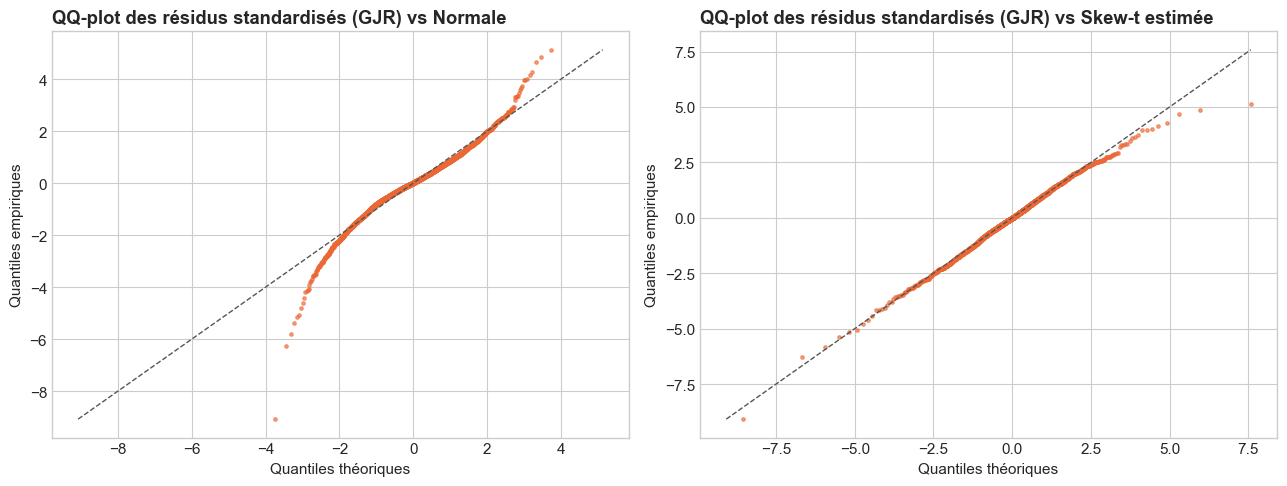

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
res_best = fitted[(BEST[0], DIST)]
z = res_best.std_resid.dropna().sort_values().values
pp = (np.arange(1, len(z) + 1) - 0.5) / len(z)
dist_obj = res_best.model.distribution
dist_params = res_best.params[dist_obj.parameter_names()].values

for ax, (theo, label) in zip(axes, [(stats.norm.ppf(pp), "Normale"),
                                     (dist_obj.ppf(pp, dist_params), "Skew-t estimée")]):
    ax.scatter(theo, z, s=6, color=COL[BEST[0]], alpha=0.6)
    lim = [min(theo.min(), z.min()), max(theo.max(), z.max())]
    ax.plot(lim, lim, color=COL["data"], lw=1, ls="--")
    ax.set_title(f"QQ-plot des résidus standardisés ({BEST[0]}) vs {label}", fontweight="bold", loc="left")
    ax.set_xlabel("Quantiles théoriques"); ax.set_ylabel("Quantiles empiriques")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_qqplot.png", dpi=200)
plt.show()

**Commentaire.** Contre la loi normale, on observe la forme en S typique de queues épaisses : le choc à −9 écarts-types (krach du 15 avril 2013) aurait une probabilité quasi nulle sous une loi normale. Contre la Skew-t estimée, les points suivent la diagonale. Seules quelques valeurs extrêmes s'en écartent un peu.

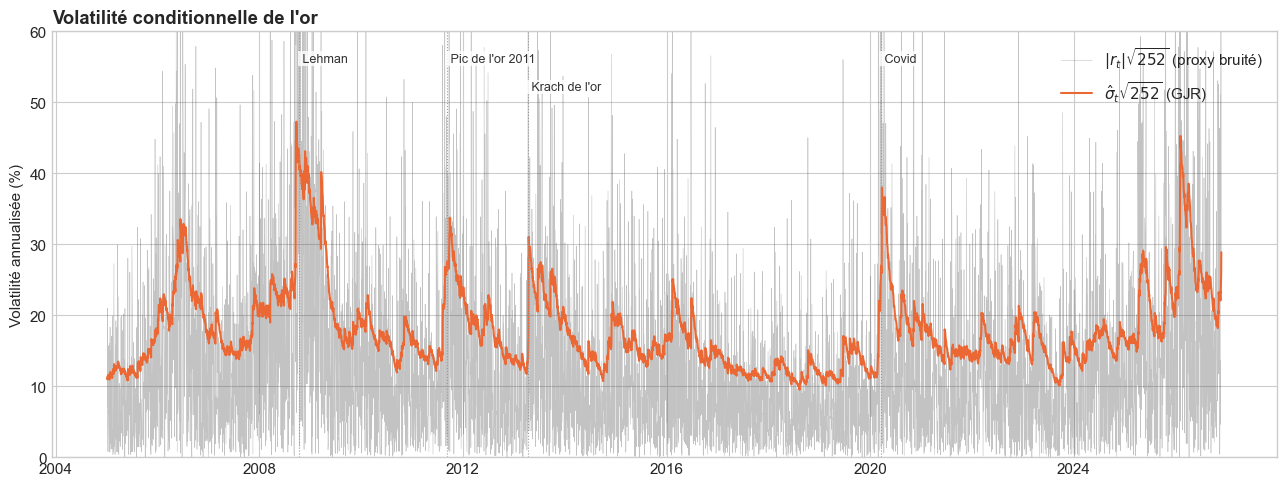

In [13]:
# Volatilité conditionnelle annualisée, modèle retenu estimé sur tout l'échantillon
res_full = arch_model(r, mean="Constant", dist=DIST, **VOL_SPECS[BEST[0]]).fit(disp="off")
vol_ann = res_full.conditional_volatility * np.sqrt(252)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(r.index, r.abs() * np.sqrt(252), color=COL["data"], lw=0.4, alpha=0.35,
        label=r"$|r_t|\sqrt{252}$ (proxy bruité)")
ax.plot(vol_ann.index, vol_ann, color=COL[BEST[0]], lw=1.5, label=rf"$\hat\sigma_t\sqrt{{252}}$ ({BEST[0]})")
for date, label, y in [("2008-10-15", "Lehman", 57), ("2011-09-06", "Pic de l'or 2011", 57),
                       ("2013-04-15", "Krach de l'or", 53), ("2020-03-16", "Covid", 57)]:
    d = pd.Timestamp(date)
    ax.axvline(d, color="#999999", lw=0.8, ls=":")
    ax.text(d, y, " " + label, fontsize=9, va="top", ha="left", color="#333333",
            bbox=dict(facecolor="white", edgecolor="none", pad=1, alpha=0.8))
ax.set_ylim(0, 60)
ax.set_ylabel("Volatilité annualisée (%)")
ax.set_title("Volatilité conditionnelle de l'or", fontweight="bold", loc="left")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_conditional_volatility.png", dpi=200)
plt.show()

## 6. Covariables : dans la moyenne et dans la variance

On part du modèle univarié retenu (GJR-GARCH(1,1) Skew-t) et on l'enrichit :
$$r_t = c + \phi^\top X_{t-1} + \varepsilon_t,\qquad
\sigma_t^2 = \omega + \big(\alpha + \gamma\,\mathbb 1_{\{\varepsilon_{t-1}<0\}}\big)\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2 + \delta^\top Z_{t-1},\qquad \delta \ge 0 .$$
- $X_{t-1}$ : variations de la veille (dollar, VIX, taux, pétrole, S&P 500).
- $Z_{t-1}$ : grandeurs **positives** de la veille (VIX², chocs au carré), d'où la contrainte $\delta \ge 0$ qui garantit $\sigma_t^2 > 0$. C'est un **GARCH-X**.

### 6.1 Corrélations avec le rendement de l'or

Corrélation de $r_t$ avec les covariables **du même jour** (information non disponible pour prévoir) et **de la veille** (ce qu'on peut utiliser). Même chose pour $r_t^2$ et les variables de variance.

In [14]:
same_day = feat.loc[train.index].corrwith(train)
lagged = data.loc[train.index, MEAN_VARS].corrwith(train)
corr_mean = pd.DataFrame({"corr(r_t, X_t) même jour": same_day, "corr(r_t, X_{t-1}) veille": lagged})
corr_var = pd.DataFrame({"corr(r_t^2, Z_{t-1})": data.loc[train.index, ["v_" + v for v in VAR_VARS]]
                         .corrwith(train**2).values}, index=VAR_VARS)
print(corr_mean.round(3)); print(); print(corr_var.round(3))

       corr(r_t, X_t) même jour  corr(r_t, X_{t-1}) veille
DXY                      -0.381                     -0.055
dVIX                     -0.022                     -0.058
dTNX                     -0.160                     -0.041
OIL                       0.160                      0.022
SP500                     0.043                      0.045

         corr(r_t^2, Z_{t-1})
VIX2                    0.197
SP500_2                 0.149
DXY_2                   0.087
OIL_2                   0.029
dTNX_2                  0.163


**Commentaire.**
- **Le même jour,** l'or est nettement lié au dollar (corrélation −0,38), aux taux (−0,16) et au pétrole (+0,16). Mais cette information n'est pas disponible au moment de prévoir.
- **La veille,** toutes les corrélations sont très faibles (|corr| < 0,06). On ne peut donc espérer qu'un gain modeste sur la prévision de $r_t$.
- **Pour la variance,** c'est plus prometteur : $r_t^2$ est corrélé au VIX² de la veille (0,20), aux chocs de taux (0,16) et du S&P 500 (0,15). Le stress de marché de la veille annonce une volatilité plus forte de l'or.

### 6.2 Estimation : QMLE codée à la main

`arch` accepte des covariables dans la moyenne (`x=`), mais **pas dans la variance**. On écrit donc la vraisemblance du GJR-GARCH-X Skew-t (même démarche qu'en section 3.2), en réutilisant la densité Skew-t de `arch`. Le modèle sans covariables est un cas particulier ($\phi = 0$, $\delta = 0$). On vérifie qu'on retrouve bien les estimations de `arch`.

Pour comparer les modèles emboîtés : **test du rapport de vraisemblance** $LR = 2(\ell_1 - \ell_0)$.
- Pour $\phi$ (pas de contrainte) : $LR \sim \chi^2_k$.
- Pour un $\delta_j$ (contraint à $\ge 0$, testé **au bord** de l'espace des paramètres) : $LR \sim \tfrac12\chi^2_0 + \tfrac12\chi^2_1$, donc la p-value est **la moitié** de celle du $\chi^2_1$.

In [15]:
from arch.univariate import SkewStudent

SKEWT = SkewStudent()
V0 = train.var()   # initialisation de sigma^2 (identique en train et en prévision)

def gjrx_filter(theta, y, Xm, Xv):
    """Renvoie (mu_t, eps_t, sigma2_t) du GJR-GARCH-X. mu_t et sigma2_t ne dépendent que de l'info en t-1."""
    km, kv = Xm.shape[1], Xv.shape[1]
    c, phi = theta[0], theta[1 : 1 + km]
    omega, alpha, gamma, beta = theta[1 + km : 5 + km]
    delta = theta[5 + km : 5 + km + kv]
    mu = c + Xm @ phi
    eps = y - mu
    e2_lag = np.r_[V0, eps[:-1] ** 2]
    neg_lag = np.r_[0.5, (eps[:-1] < 0).astype(float)]
    drive = omega + (alpha + gamma * neg_lag) * e2_lag + Xv @ delta
    sigma2 = lfilter([1], [1, -beta], drive, zi=[beta * V0])[0]
    return mu, eps, sigma2

def gjrx_loglik_obs(theta, y, Xm, Xv):
    _, eps, sigma2 = gjrx_filter(theta, y, Xm, Xv)
    if np.any(sigma2 <= 0) or not np.all(np.isfinite(sigma2)):
        return np.full(len(y), -1e6)
    return SKEWT.loglikelihood(theta[-2:], eps, sigma2, individual=True)

def fit_gjrx(mean_vars=(), var_vars=(), sample=None):
    """QMLE du GJR-GARCH-X Skew-t sur `sample` (train par défaut). Renvoie un dict de résultats."""
    idx = train.index if sample is None else sample
    y = data.loc[idx, "r"].values
    Xm = data.loc[idx, list(mean_vars)].values.reshape(len(idx), -1)
    Xv = data.loc[idx, ["v_" + v for v in var_vars]].values.reshape(len(idx), -1)
    km, kv = Xm.shape[1], Xv.shape[1]
    p0 = fitted[("GJR", "skewt")].params
    theta0 = np.r_[p0["mu"], np.zeros(km), p0["omega"], p0["alpha[1]"], p0["gamma[1]"], p0["beta[1]"],
                   np.full(kv, 1e-3), p0["eta"], p0["lambda"]]
    bounds = ([(None, None)] * (1 + km) + [(1e-6, None), (0, 1), (-1, 1), (0, 0.9999)]
              + [(0, None)] * kv + [(2.05, 100), (-0.99, 0.99)])
    obj = lambda th: -gjrx_loglik_obs(th, y, Xm, Xv).sum()
    opt = minimize(obj, theta0, method="L-BFGS-B", bounds=bounds)
    names = (["c"] + [f"phi_{v}" for v in mean_vars] + ["omega", "alpha", "gamma", "beta"]
             + [f"delta_{v}" for v in var_vars] + ["eta", "lambda"])
    return {"theta": opt.x, "names": names, "ll": -opt.fun, "k": len(opt.x), "n": len(y),
            "bic": 2 * opt.fun + len(opt.x) * np.log(len(y)), "y": y, "Xm": Xm, "Xv": Xv,
            "mean_vars": list(mean_vars), "var_vars": list(var_vars), "converged": opt.success}

def robust_table(fit):
    """Écarts-types robustes (sandwich) par différences finies."""
    th, y, Xm, Xv = fit["theta"], fit["y"], fit["Xm"], fit["Xv"]
    S = num_jacobian(lambda t: gjrx_loglik_obs(t, y, Xm, Xv), th)
    H = num_jacobian(lambda t: num_jacobian(lambda u: gjrx_loglik_obs(u, y, Xm, Xv), t).sum(0), th, h=1e-4)
    Hi = np.linalg.inv(H)
    se = np.sqrt(np.abs(np.diag(Hi @ (S.T @ S) @ Hi)))
    out = pd.DataFrame({"coef": th, "e.-t. robuste": se}, index=fit["names"])
    out["p-value"] = 2 * (1 - stats.norm.cdf(np.abs(out["coef"] / out["e.-t. robuste"])))
    return out

base = fit_gjrx()
ref = fitted[("GJR", "skewt")]
print(f"Vérification sans covariables : LL maison = {base['ll']:.2f} | LL arch = {ref.loglikelihood:.2f}")
print(pd.DataFrame({"maison": base["theta"],
                    "arch": ref.params[["mu", "omega", "alpha[1]", "gamma[1]", "beta[1]", "eta", "lambda"]].values},
                   index=base["names"]).round(4))

Vérification sans covariables : LL maison = -7893.96 | LL arch = -7892.67
        maison    arch
c       0.0421  0.0417
omega   0.0073  0.0072
alpha   0.0546  0.0533
gamma  -0.0279 -0.0273
beta    0.9569  0.9579
eta     4.6971  4.6974
lambda -0.0580 -0.0578


*Le petit écart de log-vraisemblance vient de l'initialisation de $\sigma_0^2$ (variance empirique ici, « backcast » pondéré dans `arch`). Il n'affecte pas les estimations.*

### 6.3 Covariables dans la moyenne

In [16]:
fit_mean = fit_gjrx(mean_vars=MEAN_VARS)
lr = 2 * (fit_mean["ll"] - base["ll"])
print(f"LR (5 covariables dans la moyenne) = {lr:.2f}, p-value (chi2_5) = {1 - stats.chi2.cdf(lr, 5):.2e}\n")
tab_mean = robust_table(fit_mean)
print(tab_mean.round(4))

# Contrôle avec arch (même modèle, moyenne ARX)
arx = arch_model(train, x=data.loc[train.index, MEAN_VARS], mean="ARX", lags=0, vol="GARCH",
                 p=1, o=1, q=1, dist="skewt").fit(disp="off")
print("\nContrôle arch (coefficients de moyenne, p-values robustes) :")
print(pd.DataFrame({"coef": arx.params[["Const"] + MEAN_VARS], "p-value": arx.pvalues[["Const"] + MEAN_VARS]}).round(4))

LR (5 covariables dans la moyenne) = 29.13, p-value (chi2_5) = 2.18e-05



             coef  e.-t. robuste  p-value
c          0.0425         0.0134   0.0016
phi_DXY    0.0122         0.0304   0.6872
phi_dVIX  -0.0065         0.0026   0.0124
phi_dTNX  -0.0086         0.0026   0.0010
phi_OIL    0.0047         0.0054   0.3854
phi_SP500  0.0117         0.0234   0.6152
omega      0.0071         0.0023   0.0026
alpha      0.0557         0.0079   0.0000
gamma     -0.0296         0.0084   0.0004
beta       0.9570         0.0053   0.0000
eta        4.6973         0.3117   0.0000
lambda    -0.0596         0.0177   0.0008



Contrôle arch (coefficients de moyenne, p-values robustes) :
         coef  p-value
Const  0.0420   0.0017
DXY    0.0092   0.7617
dVIX  -0.0065   0.0128
dTNX  -0.0085   0.0011
OIL    0.0044   0.4115
SP500  0.0118   0.6154


**Commentaire.**
- **Code maison et `arch` concordent** : mêmes signes, mêmes ordres de grandeur, et p-values quasi identiques pour les variables significatives.
- Ensemble, les 5 covariables sont **significatives** (LR = 29,1, p = 2·10⁻⁵).
- Individuellement, seules deux le sont (p-values robustes) :
  - **`dVIX`** (φ = −0,0065, p = 0,012) : si le VIX a monté de 10 % la veille, l'or baisse en moyenne de 0,065 % aujourd'hui ;
  - **`dTNX`** (φ = −0,0086, p = 0,001) : une hausse de 10 points de base du taux à 10 ans la veille fait baisser l'or de ≈ 0,09 %. C'est cohérent avec le coût d'opportunité de l'or.
- Le dollar, le pétrole et le S&P 500 de la veille n'apportent rien.
- *Hypothèse à vérifier :* une partie de cet effet retardé peut venir des **horaires de clôture** différents (le prix de l'or peut être fixé avant la clôture de Wall Street). Les nouvelles de fin de journée seraient alors intégrées par l'or seulement le lendemain.
- Les effets restent **petits** : quelques centièmes de % par jour, pour un écart-type de ≈ 1,2 %.

### 6.4 Covariables dans la variance (GARCH-X)

On ajoute les variables de variance **une par une** au GJR (moyenne constante), et on teste chacune par un LR au bord.

In [17]:
rows = []
for v in VAR_VARS:
    f = fit_gjrx(var_vars=[v])
    lr = max(2 * (f["ll"] - base["ll"]), 0)
    rows.append({"variable": v, "delta": f["theta"][f["names"].index(f"delta_{v}")], "LR": lr,
                 "p-value (au bord)": 0.5 * (1 - stats.chi2.cdf(lr, 1)), "BIC": f["bic"]})
tab_var = pd.DataFrame(rows).set_index("variable")
print(f"Référence GJR sans covariables : BIC = {base['bic']:.1f}\n")
print(tab_var.round(4))

Référence GJR sans covariables : BIC = 15848.2

           delta       LR  p-value (au bord)         BIC
variable                                                
VIX2      0.0043   5.6976             0.0085  15851.1135
SP500_2   0.0052  12.1921             0.0002  15844.6190
DXY_2     0.0137   1.6478             0.0996  15855.1633
OIL_2     0.0000   0.0000             0.5000  15856.8113
dTNX_2    0.0115   3.0356             0.0407  15853.7755


**Commentaire.**
- Prises **une par une**, trois variables sont significatives : les chocs du S&P 500 (LR = 12,2, p = 0,0002), le VIX² (p = 0,009) et les chocs de taux (p = 0,04). Les chocs du dollar ne le sont pas (p = 0,10), et ceux du pétrole donnent $\hat\delta = 0$.
- **Mais seule `SP500_2` améliore le BIC** (15844,6 contre 15848,2). Ces variables mesurent toutes le stress de marché de la veille et sont donc redondantes entre elles, d'où la sélection pas à pas de la section 6.5.

### 6.5 Modèle final avec covariables

- **Moyenne :** on garde les covariables significatives à 5 % (p-value robuste de la section 6.3).
- **Variance :** les variables de variance sont très corrélées entre elles (VIX², chocs du S&P 500 et des taux mesurent tous le stress de marché). Les tester une par une ne suffit donc pas. On fait une **sélection pas à pas par BIC** : on ajoute à chaque étape la variable qui fait le plus baisser le BIC, et on s'arrête quand plus aucune ne l'améliore.

On ré-estime ensuite le modèle conjoint et on compare les 4 spécifications.

In [18]:
SEL_MEAN = [v for v in MEAN_VARS if tab_mean.loc[f"phi_{v}", "p-value"] < 0.05]
SEL_VAR, best_bic_var = [], base["bic"]
while True:
    cands = {v: fit_gjrx(var_vars=SEL_VAR + [v])["bic"] for v in VAR_VARS if v not in SEL_VAR}
    if not cands or min(cands.values()) >= best_bic_var:
        break
    v_best = min(cands, key=cands.get)
    print(f"  + {v_best:8s} BIC {best_bic_var:.1f} -> {cands[v_best]:.1f}   (autres : "
          + ", ".join(f"{k} {b:.1f}" for k, b in cands.items() if k != v_best) + ")")
    SEL_VAR.append(v_best); best_bic_var = cands[v_best]
print("Moyenne :", SEL_MEAN, "| Variance :", SEL_VAR)

fits = {
    "GJR": base,
    "GJR + X moyenne": fit_gjrx(mean_vars=SEL_MEAN),
    "GJR-X variance": fit_gjrx(var_vars=SEL_VAR),
    "GJR-X complet": fit_gjrx(mean_vars=SEL_MEAN, var_vars=SEL_VAR),
}
comp = pd.DataFrame({name: {"k": f["k"], "LL": f["ll"], "BIC": f["bic"],
                            "LR vs GJR": 2 * (f["ll"] - base["ll"])} for name, f in fits.items()}).T
print(comp.round(2))

tab_final = robust_table(fits["GJR-X complet"])
print("\nModèle complet (écarts-types robustes) :")
print(tab_final.round(4))

z_final = (lambda m, e, s2: e / np.sqrt(s2))(*gjrx_filter(fits["GJR-X complet"]["theta"], fits["GJR-X complet"]["y"],
                                                         fits["GJR-X complet"]["Xm"], fits["GJR-X complet"]["Xv"]))
print("\nDiagnostics du modèle complet (p-values) : LB z(10) = %.3f | LB z^2(10) = %.3f | ARCH-LM z(10) = %.3f" % (
    acorr_ljungbox(z_final, lags=[10])["lb_pvalue"].iloc[0],
    acorr_ljungbox(z_final**2, lags=[10])["lb_pvalue"].iloc[0], het_arch(z_final, nlags=10)[1]))

  + SP500_2  BIC 15848.2 -> 15844.6   (autres : VIX2 15851.1, DXY_2 15855.2, OIL_2 15856.8, dTNX_2 15853.8)


Moyenne : ['dVIX', 'dTNX'] | Variance : ['SP500_2']


                    k       LL       BIC  LR vs GJR
GJR               7.0 -7893.96  15848.20       0.00
GJR + X moyenne   9.0 -7880.00  15837.51      27.92
GJR-X variance    8.0 -7887.86  15844.62      12.19
GJR-X complet    10.0 -7874.10  15834.33      39.70

Modèle complet (écarts-types robustes) :
                 coef  e.-t. robuste  p-value
c              0.0431         0.0133   0.0012
phi_dVIX      -0.0078         0.0017   0.0000
phi_dTNX      -0.0079         0.0025   0.0014
omega          0.0073         0.0026   0.0055
alpha          0.0526         0.0079   0.0000
gamma         -0.0263         0.0087   0.0025
beta           0.9535         0.0065   0.0000
delta_SP500_2  0.0050         0.0021   0.0163
eta            4.6977         0.3026   0.0000
lambda        -0.0611         0.0175   0.0005



Diagnostics du modèle complet (p-values) : LB z(10) = 0.757 | LB z^2(10) = 0.141 | ARCH-LM z(10) = 0.151


**Commentaire.**
- **Sélection :** la sélection pas à pas par BIC ne retient que `SP500_2` dans la variance. Une fois les chocs du S&P 500 inclus, ni le VIX² ni les chocs de taux n'apportent d'information supplémentaire.
- **Comparaison des 4 modèles :** le **GJR-X complet** a le meilleur BIC (15834,3 contre 15848,2 sans covariables, LR = 39,7 pour 3 paramètres). Les deux apports se cumulent : la moyenne fait gagner ≈ 11 points de BIC, la variance ≈ 3,5.
- **Coefficients :**
  - dans la moyenne, `dVIX` (−0,0078) et `dTNX` (−0,0079) sont significatifs (p ≤ 0,001) ;
  - dans la variance, $\delta_{SP500^2} = 0{,}005$ (p = 0,016). Un jour normal, l'effet est faible : un mouvement de 2 % du S&P 500 ajoute 0,02 %² à $\sigma_t^2$. Un jour de krach, il devient important : le −12,8 % de mars 2020 ajoute ≈ 0,8 %², soit ≈ 60 % de la variance journalière moyenne de l'or (≈ 1,37 %²).
  - $\beta$ baisse légèrement (0,957 → 0,954) : une partie de la persistance est expliquée par les chocs extérieurs.
- **Diagnostics :** le modèle passe tous les tests (LB $z$ : p = 0,76 ; LB $z^2$ : p = 0,14 ; ARCH-LM : p = 0,15). C'est le **modèle retenu** pour la prévision.

## 7. Prévision des 3 jours de test

Les paramètres sont estimés **sur le train uniquement**, puis fixés. Chaque jour de test, on prévoit le lendemain ($h = 1$) avec l'information disponible la veille : le dernier choc $\varepsilon_{t-1}$, la dernière variance $\sigma^2_{t-1}$ et les covariables de la veille. Comme $\mu_t$ et $\sigma_t^2$ ne dépendent que du passé, il suffit de faire tourner le filtre sur tout l'échantillon et de lire les 3 dernières valeurs.

En prix : $\hat P_t = P_{t-1}\,e^{\hat\mu_t/100}$, et l'intervalle à 80 % vaut $\big[P_{t-1}e^{\hat q_{10\%}/100},\; P_{t-1}e^{\hat q_{90\%}/100}\big]$.

On compare au **naïf** ($\hat r_t = 0$, donc $\hat P_t = P_{t-1}$) et à **Chronos-2** (`preds_chronos.csv`, mêmes dates).

In [19]:
def forecast_test(fit):
    idx = r.index
    y = data["r"].values
    Xm = data[fit["mean_vars"]].values.reshape(len(idx), -1)
    Xv = data[["v_" + v for v in fit["var_vars"]]].values.reshape(len(idx), -1)
    mu, _, s2 = gjrx_filter(fit["theta"], y, Xm, Xv)
    out = pd.DataFrame({"mu": mu, "sigma": np.sqrt(s2)}, index=idx).iloc[-N_TEST:]
    qz = SKEWT.ppf([0.01, 0.05, 0.10, 0.90], fit["theta"][-2:])
    for lev, q in zip(["q01", "q05", "q10", "q90"], qz):
        out[lev] = out["mu"] + out["sigma"] * q
    return out

fc = {name: forecast_test(f) for name, f in fits.items()}

chronos = pd.read_csv(DATA_DIR / "preds_chronos.csv", parse_dates=["Date"]).set_index("Date")
p_prev = price.shift(1).loc[test.index]       # P_{t-1}
p_true = price.loc[test.index]

table = pd.DataFrame({"r réel (%)": test, "P_{t-1}": p_prev, "P réel": p_true})
for name, f in fc.items():
    table[f"mu {name}"] = f["mu"]
table["sigma GJR-X complet"] = fc["GJR-X complet"]["sigma"]
table["Chronos-2 (%)"] = 100 * chronos.reindex(test.index)["pred_chronos_uni"]
print(table.round(3).T.to_string())

Date                 2026-11-20  2026-11-23  2026-11-24
r réel (%)               -4.725       3.796      -1.662
P_{t-1}                3685.500    3515.400    3651.400
P réel                 3515.400    3651.400    3591.200
mu GJR                    0.042       0.042       0.042
mu GJR + X moyenne       -0.060      -0.027       0.272
mu GJR-X variance         0.042       0.042       0.042
mu GJR-X complet         -0.060      -0.027       0.271
sigma GJR-X complet       1.452       1.631       1.849
Chronos-2 (%)            -0.127      -0.280      -0.065


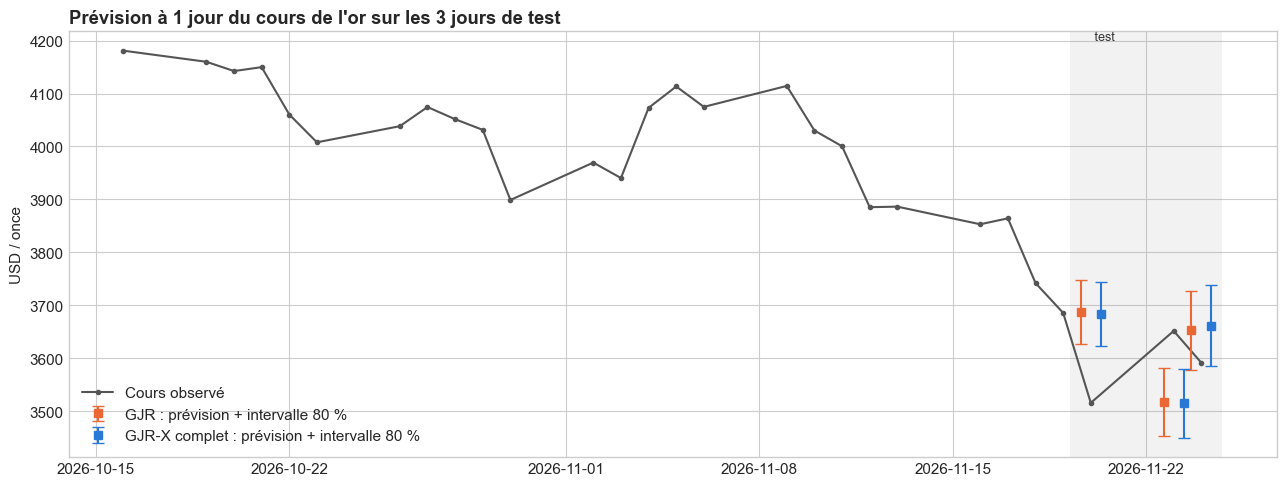

In [20]:
hist = price.iloc[-(N_TEST + 25):]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(hist.index, hist, color=COL["data"], marker="o", markersize=3, label="Cours observé")
offsets = {"GJR": -0.12, "GJR-X complet": 0.12}
for name, off in offsets.items():
    f = fc[name]
    d = test.index + pd.Timedelta(days=off * 3)
    lo, hi = p_prev * np.exp(f["q10"] / 100), p_prev * np.exp(f["q90"] / 100)
    ax.errorbar(d, p_prev * np.exp(f["mu"] / 100), yerr=[p_prev * np.exp(f["mu"] / 100) - lo, hi - p_prev * np.exp(f["mu"] / 100)],
                fmt="s", color=COL["GJR"] if name == "GJR" else COL["GARCH"], capsize=4, markersize=6,
                label=f"{name} : prévision + intervalle 80 %")
ax.axvspan(test.index[0] - pd.Timedelta(hours=18), test.index[-1] + pd.Timedelta(hours=18), color="#999999", alpha=0.12, lw=0)
ax.text(test.index[0], ax.get_ylim()[1], " test", va="top", fontsize=9, color="#333333")
ax.set_ylabel("USD / once")
ax.set_title("Prévision à 1 jour du cours de l'or sur les 3 jours de test", fontweight="bold", loc="left")
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_test_3days.png", dpi=200)
plt.show()

**Commentaire.** Les 3 jours de test sont très agités :
- **20 novembre : −4,7 %**, en pleine envolée du VIX (28 → 36) ;
- **23 novembre : +3,8 %** (rebond, VIX en baisse de 30 %) ;
- **24 novembre : −1,7 %**.

Ce sont des chocs de 3,3 et 2,3 écarts-types prévus pour les deux premiers jours. Aucun modèle ne pouvait les anticiper.
- **Les prévisions de rendement restent proches de 0** (|μ̂| < 0,3 %), ce qui est attendu pour un actif quasi imprévisible.
- La prévision du GJR-X complet pour le 24 novembre (+0,27 %) vient de la **chute de 30 % du VIX la veille** : $-0{,}0078 \times (-29{,}9) \approx +0{,}23\,\%$. Le mécanisme fonctionne comme prévu, mais l'or a baissé ce jour-là.
- **La volatilité prévue réagit :** $\hat\sigma$ passe de 1,45 % à 1,85 % après le choc du 20 novembre. L'intervalle à 80 % s'élargit donc d'un jour à l'autre. Seul le 24 novembre tombe dans l'intervalle.

## 8. Évaluation sur les 3 jours de test

- **Rendements** : MAE et RMSE de $\hat\mu_t$ (en %).
- **Prix** : MAE et RMSE de $\hat P_t$ (en USD).
- **Volatilité** : QLIKE moyenne $\ln\hat\sigma_t^2 + r_t^2/\hat\sigma_t^2$ (plus petit = mieux).
- **Intervalle 80 %** : nombre de jours où le rendement réalisé tombe dedans (sur 3).

⚠️ Avec $n = 3$, un seul jour agité suffit à changer le classement. Ces chiffres **illustrent** le comportement des modèles mais ne permettent **aucune conclusion statistique**. Les arguments solides sont les tests sur le train (section 6).

In [21]:
def metrics(mu, sigma=None, q10=None, q90=None):
    e = test - mu
    p_hat = p_prev * np.exp(mu / 100)
    out = {"MAE r (%)": np.mean(np.abs(e)), "RMSE r (%)": np.sqrt(np.mean(e**2)),
           "MAE prix ($)": np.mean(np.abs(p_true - p_hat)), "RMSE prix ($)": np.sqrt(np.mean((p_true - p_hat) ** 2))}
    if sigma is not None:
        out["QLIKE"] = np.mean(np.log(sigma**2) + test**2 / sigma**2)
        out["dans IC 80 % (sur 3)"] = int(np.sum((test >= q10) & (test <= q90)))
    return out

zero = pd.Series(0.0, index=test.index)
ev = {"Naïf (r = 0)": metrics(zero),
      "Chronos-2 univarié": metrics(100 * chronos.reindex(test.index)["pred_chronos_uni"]),
      "Chronos-2 + covariables": metrics(100 * chronos.reindex(test.index)["pred_chronos_multi"])}
for name, f in fc.items():
    ev[name] = metrics(f["mu"], f["sigma"], f["q10"], f["q90"])
eval_table = pd.DataFrame(ev).T
fmt_cols = {"MAE r (%)": "{:.3f}", "RMSE r (%)": "{:.3f}", "MAE prix ($)": "{:.1f}", "RMSE prix ($)": "{:.1f}",
            "QLIKE": "{:.3f}", "dans IC 80 % (sur 3)": "{:.0f}"}
print(eval_table.apply(lambda col: col.map(lambda v: "—" if pd.isna(v) else fmt_cols[col.name].format(v))).to_string())

                        MAE r (%) RMSE r (%) MAE prix ($) RMSE prix ($)  QLIKE dans IC 80 % (sur 3)
Naïf (r = 0)                3.394      3.629        122.1         130.5      —                    —
Chronos-2 univarié          3.424      3.666        123.0         131.6      —                    —
Chronos-2 + covariables     3.440      3.780        123.3         135.4      —                    —
GJR                         3.409      3.639        122.6         130.9  6.610                    1
GJR + X moyenne             3.474      3.657        125.0         131.5  6.618                    1
GJR-X variance              3.408      3.639        122.6         130.9  6.570                    1
GJR-X complet               3.474      3.657        125.0         131.5  6.591                    1


**Commentaire.**
- **En prix,** le naïf a le plus petit RMSE (130,5 \$). Le GJR (130,9 \$), le GJR-X complet (131,5 \$) et Chronos-2 (131,6 à 135,4 \$) suivent. Les écarts sont de **1 à 5 \$ sur une erreur de 130 \$** : c'est du bruit. Sur 3 jours, ce classement n'a aucune valeur statistique.
- **En volatilité (QLIKE),** les modèles avec covariables dans la variance font un peu mieux (6,57 pour le GJR-X variance, 6,59 pour le complet, contre 6,61 pour le GJR). Après le choc du 20 novembre, ils ont prévu une volatilité plus élevée, ce qui correspond à ce qui s'est passé.
- **Intervalle à 80 % :** 1 jour sur 3 dans l'intervalle pour tous les modèles (2,4 attendus). C'est explicable par deux chocs de 2 à 3 écarts-types consécutifs, et non significatif avec 3 observations.
- **À retenir :** le choix du modèle repose sur les tests faits sur 5 500 jours (section 6). Les 3 jours de test servent d'illustration de l'usage du modèle, pas de preuve de sa supériorité.

## 9. Export pour `06_evaluation.ipynb`

Une ligne par jour de test, en **unités brutes** (log-rendements, pas en %) comme `preds_chronos.csv`. Les colonnes principales (`pred_mean`, `sigma`, `q10`, `q90`, `VaR_1`, `VaR_5`) correspondent au modèle complet. On ajoute $\hat\mu$ et $\hat\sigma$ de chaque variante, ainsi que les prix réels et prévus.

In [22]:
f = fc["GJR-X complet"]
export = pd.DataFrame({
    "Date": test.index, "y_true": test.values / 100,
    "pred_mean": f["mu"].values / 100, "sigma": f["sigma"].values / 100,
    "q10": f["q10"].values / 100, "q90": f["q90"].values / 100,
    "VaR_1": f["q01"].values / 100, "VaR_5": f["q05"].values / 100,
    "price_prev": p_prev.values, "price_true": p_true.values,
    "price_pred": (p_prev * np.exp(f["mu"] / 100)).values,
})
KEYS = {"GJR": "gjr", "GJR + X moyenne": "gjr_xmean", "GJR-X variance": "gjrx_var", "GJR-X complet": "gjrx_full"}
for name, ff in fc.items():
    key = KEYS[name]
    export[f"pred_mean_{key}"] = ff["mu"].values / 100
    export[f"sigma_{key}"] = ff["sigma"].values / 100
export.to_csv(DATA_DIR / "preds_garch.csv", index=False)
print(f"-> data/preds_garch.csv  {export.shape}")
export.T

-> data/preds_garch.csv  (3, 19)


,0,1,2
Date,2026-11-20 00:00:00,2026-11-23 00:00:00,2026-11-24 00:00:00
y_true,-0.047253,0.037957,-0.016624
pred_mean,-0.000599,-0.000269,0.002707
sigma,0.014518,0.016308,0.018485
q10,-0.017227,-0.018947,-0.018466
q90,0.015542,0.017862,0.023259
VaR_1,-0.040279,-0.04484,-0.047816
VaR_5,-0.023692,-0.026209,-0.026697
price_prev,3685.5,3515.399902,3651.399902
price_true,3515.399902,3651.399902,3591.199951


## 10. Conclusion

1. **La moyenne est presque imprévisible.** Sans covariables, le BIC retient une constante. L'autocorrélation apparente de $r_t$ disparaît sur les résidus standardisés, et un ARMA(1,1) n'est pas identifié ($\hat a \approx \hat b$). Avec covariables, les variations **de la veille** du VIX et du taux à 10 ans sont significatives (une hausse fait baisser l'or), mais leur effet est de quelques centièmes de %.
2. **La volatilité est très prévisible et persistante :** $\alpha+\beta \approx 0{,}996$ (demi-vie ≈ 180 jours), et la mémoire longue est confirmée par GPH ($\hat d \approx 0{,}42$ sur $|r_t|$) et par le FIGARCH ($\hat d = 0{,}42$). Le FIGARCH n'améliore toutefois pas le BIC.
3. **Effet de levier inversé :** la volatilité de l'or augmente davantage après une hausse qu'après une baisse, ce qui est cohérent avec son rôle de valeur refuge.
4. **Modèle retenu : GJR-GARCH-X(1,1) Skew-t,** avec `dVIX` et `dTNX` de la veille dans la moyenne et les chocs du S&P 500 de la veille dans la variance. C'est le meilleur BIC (−14 points par rapport au GJR sans covariables), et il passe tous les diagnostics.
5. **Test sur 3 jours :** toutes les méthodes (naïf, GARCH, Chronos-2) font jeu égal à quelques dollars près, sur 3 jours exceptionnellement agités. La volatilité prévue réagit bien au choc.

**Limites et pistes :**
- Évaluer sur une fenêtre de test plus longue (walk-forward), pour pouvoir tester statistiquement l'apport des covariables hors échantillon et backtester la VaR.
- Vérifier les horaires de clôture (or contre Wall Street) pour l'effet retardé du VIX et des taux.
- Prévoir à plusieurs jours (h = 2, 3), ce qui demande de prévoir aussi les covariables.
- Tester des ruptures de régime, qui peuvent créer une fausse mémoire longue.

## Annexe : simulation de l'Atelier 2 (ARMA(1,1) à erreurs ARCH(1))

Portage Python de l'exercice 1 de l'Atelier 2 :
$$X_t = aX_{t-1} + \varepsilon_t - b\,\varepsilon_{t-1},\qquad \varepsilon_t = \sigma_t\eta_t,\quad \sigma_t^2 = \omega + \alpha\varepsilon_{t-1}^2 .$$
Avec $|a|<1$ (et $|b|<1$ pour l'inversibilité), $X$ est stationnaire au second ordre dès que $\varepsilon$ l'est, c'est-à-dire si $\alpha < 1$. On simule 500 trajectoires de taille 3000 avec $a=-0.4$, $b=0.7$, $\omega=1$, et on étudie l'estimateur des moindres carrés $(\hat a_n, \hat b_n) = \arg\min_{[-1,1]^2} Q_n(a,b)$ pour trois valeurs de $\alpha$ :
- $\alpha = 0$ : bruit iid (cas classique) ;
- $\alpha = 0.3$ : ARCH avec $3\alpha^2 < 1$, donc $\mathbb E[\varepsilon_t^4] < \infty$ ;
- $\alpha = 0.6$ (valeur du TP) : $3\alpha^2 = 1.08 > 1$, donc **$\mathbb E[\varepsilon_t^4] = \infty$**. Les conditions de moments habituelles du TCL de l'estimateur des MCO (Francq & Zakoïan, 1998) ne sont plus garanties.

In [23]:
rng = np.random.default_rng(SEED)

def Eps(n, omega, alpha, burn=500):
    eta = rng.standard_normal(n + burn)
    eps = np.zeros(n + burn)
    for t in range(1, n + burn):
        eps[t] = np.sqrt(omega + alpha * eps[t - 1] ** 2) * eta[t]
    return eps[burn:]

def SimProcess(n, a, b, omega, alpha, burn=500):
    eps = Eps(n + burn, omega, alpha, burn=0)
    return lfilter([1, -b], [1, -a], eps)[burn:]           # (1 - aL) X = (1 - bL) eps

def Objective(theta, X):
    a, b = theta
    eps = lfilter([1, -a], [1, -b], X)                       # eps_t = X_t - a X_{t-1} + b eps_{t-1}
    return np.mean(eps**2)

def ls_estimate(X):
    return minimize(Objective, x0=[0.5, 0.5], args=(X,), method="L-BFGS-B", bounds=[(-1, 1), (-1, 1)]).x

# Une trajectoire : moindres carrés vs ARIMA de statsmodels (b = -ma.L1)
X = SimProcess(3000, -0.4, 0.7, 1, 0.6)
fit_sm = ARIMA(X, order=(1, 0, 1), trend="n").fit()
print("Moindres carrés  : a = %.3f, b = %.3f" % tuple(ls_estimate(X)))
print("statsmodels ARIMA: a = %.3f, b = %.3f" % (fit_sm.params[0], -fit_sm.params[1]))
print("Écarts-types 'iid' renvoyés par ARIMA : ", fit_sm.bse[:2].round(4))

Moindres carrés  : a = -0.392, b = 0.708
statsmodels ARIMA: a = -0.393, b = 0.707
Écarts-types 'iid' renvoyés par ARIMA :  [0.0103 0.0085]


             biais  sqrt(n) x écart-type  kurtosis excès  Shapiro p
alpha param                                                        
0.0   a     -0.000                 1.027          -0.128      0.192
      b     -0.001                 0.843          -0.058      0.392
0.3   a      0.000                 1.236           0.388      0.372
      b      0.000                 0.930           0.140      0.954
0.6   a      0.002                 2.415          15.212      0.000
      b     -0.002                 2.101          42.735      0.000


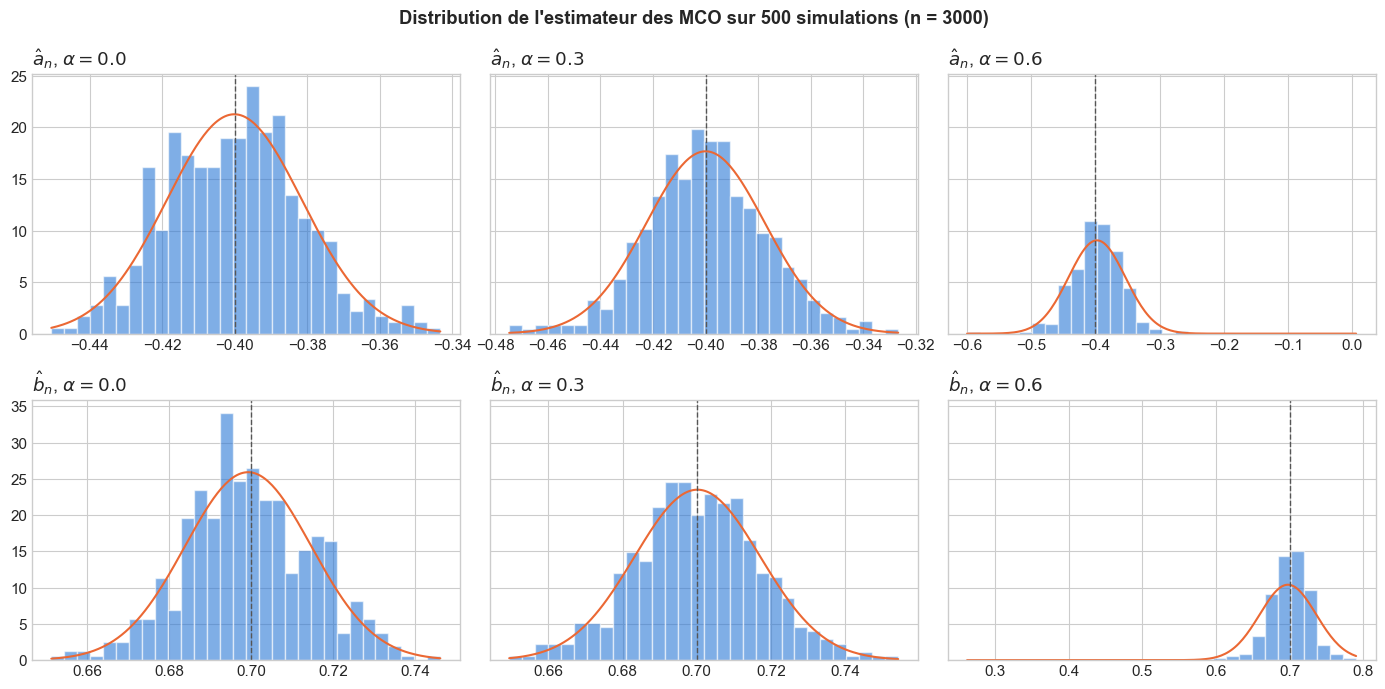

In [24]:
N_SIM, n = 500, 3000
mc = {}
for alpha in (0.0, 0.3, 0.6):
    mc[alpha] = np.array([ls_estimate(SimProcess(n, -0.4, 0.7, 1, alpha)) for _ in range(N_SIM)])

summary = []
for alpha, est in mc.items():
    for j, (par, true) in enumerate([("a", -0.4), ("b", 0.7)]):
        e = est[:, j]
        summary.append({"alpha": alpha, "param": par, "biais": e.mean() - true,
                        "sqrt(n) x écart-type": np.sqrt(n) * e.std(), "kurtosis excès": stats.kurtosis(e),
                        "Shapiro p": stats.shapiro(e).pvalue})
print(pd.DataFrame(summary).set_index(["alpha", "param"]).round(3))

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey="row")
for c, (alpha, est) in enumerate(mc.items()):
    for rr, (par, true) in enumerate([("a", -0.4), ("b", 0.7)]):
        ax = axes[rr, c]
        e = est[:, rr]
        ax.hist(e, bins=30, density=True, color=COL["GARCH"], alpha=0.6, edgecolor="white")
        g = np.linspace(e.min(), e.max(), 200)
        ax.plot(g, stats.norm.pdf(g, e.mean(), e.std()), color=COL["GJR"], lw=1.5)
        ax.axvline(true, color=COL["data"], ls="--", lw=1)
        ax.set_title(rf"$\hat {par}_n$, $\alpha = {alpha}$", loc="left")
plt.suptitle("Distribution de l'estimateur des MCO sur 500 simulations (n = 3000)", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_annex_mc_ls.png", dpi=200)
plt.show()

**Commentaire.**
- **Une trajectoire :** les moindres carrés (codés à la main) et `ARIMA` donnent les mêmes estimations ($\hat a \approx -0{,}39$, $\hat b \approx 0{,}71$). L'estimateur est consistant malgré les erreurs ARCH.
- **$\alpha = 0$ et $\alpha = 0{,}3$ :** les estimateurs sont sans biais et gaussiens (Shapiro non rejeté). Mais $\sqrt n \times$ écart-type de $\hat a$ passe de 1,03 à 1,24 : **l'effet ARCH gonfle la variance asymptotique** par rapport à la formule iid (matrice sandwich de Francq & Zakoïan).
- **$\alpha = 0{,}6$ (valeur du TP) :** l'estimateur reste consistant (biais ≈ 0,002), mais sa dispersion est multipliée par ≈ 2,4. Sa distribution a des **queues très épaisses** (kurtosis en excès de 15 à 43, Shapiro rejeté, quelques estimations très éloignées sur les histogrammes). Comme $\mathbb E[\varepsilon_t^4] = \infty$, l'approximation gaussienne n'est pas fiable même avec $n = 3000$.
- **Conséquence pratique :** `ARIMA` annonce un écart-type « iid » de 0,010 pour $\hat a$, alors que l'écart-type réel en Monte Carlo est ≈ 2,415/√3000 ≈ 0,044, **4 fois plus grand**. Les tests sur les coefficients ARMA (et le Ljung-Box) sont trompeurs en présence d'effet ARCH. C'est ce qui justifie, dans le projet, les écarts-types robustes et les tests sur les résidus standardisés.

nb : garch ne permet pas de modeliser les valeurs futures mais est seulement utile pour la volatilté (variance non cste dans le temps). Il faut le combiner à un autre modele (arma)
Le modèle est mal spécifié car il y a de la memoire longue dans les series financières. 